# BEE 4750 Homework 6: Linear Programs and Shadow Prices

**Name**: Gina Chen, Mikael Murphy-Rendon

**ID**:cc2859, mm3446

> **Due Date**
>
> Thursday, 10/29/26, 9:00pm

## Overview

### Instructions

- Problem 1 asks you to formulate a water-supply problem as a linear
  program.
- Problem 2 asks you to interpret a linear program graphically.
- Problem 3 asks you to find the optimal solution to a stormwater plan
  and its shadow prices by hand, and to see where a shadow price stops
  being a good estimate.
- Problem 4 is a larger nutrient-management LP. The `JuMP` code that
  solves it is provided; you interpret its solution.
- Write your answers in Markdown cells. For the sketches, a photo or
  scan of a hand drawing is fine: save it in this folder and insert it
  with `![](sketch.png)`.

### Load Environment

In [1]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `~/Desktop/BEE 4750/hw06`


In [2]:
using JuMP
using HiGHS
using Plots

## Problems (Total: 50 Points)

### Problem 1 (13) 

A city of about 150,000 people supplies its drinking water from two
sources: a river intake and a groundwater well field. It must deliver at
least 20 million gallons per day (MGD). The operating cost (energy and
chemicals) of treating and pumping river water is \$300 per million
gallons; for groundwater, which has to be pumped from deeper, it is
\$500 per million gallons. The river withdrawal permit allows at most 15
MGD, and the well field can produce at most 12 MGD.

River water carries 8 mg/L of nitrate from farms upstream; the
groundwater carries 2 mg/L. To stay well below the 10 mg/L
drinking-water standard, the city requires the blended supply to average
at most 6 mg/L of nitrate. The city wants to meet demand at the lowest
daily cost.

#### Problem 1.1 (1)

Define the decision variables, with units.

**Answer:** <br>
$W_1,W_2$: volume of water per day removed at each source (MGD). Let $W_1$ represent the river intake and $W_2$ the groundwater well field.

#### Problem 1.2 (2)

What are the bounds on each decision variable, and where does each bound
come from?

**Answer:**<br>
$0 \leq W_1 \leq 15$ where the lower bound is the physical limit (volume extraction cannot be negative) and the upper bound is from the river withdrawal permit.<br>
$0 \leq W_1 \leq 12$ where the lower bound is the physical limit (volume extraction cannot be negative) and the upper bound is from the well field's production capacity.

#### Problem 1.3 (2)

Write the objective function, with units. Is the city maximizing or
minimizing it?

**Answer:**
$$ \min_{W_1, W_2} \quad 300W_1 + 500W_2 \quad [\$1/\text{MG}]$$
The city is minimizing cost.


#### Problem 1.4 (5)

Write every constraint in linear form, including the bounds from Problem
1.2, each with a short label saying what it represents and with units
that agree on both sides.

$W_1  + W_2   \geq 20  $ — city's minimum water demand<br>
$\frac{8W_1 [mg/L]}{W_1 + W_2} + \frac{2W_2 [mg/L]}{W_1 + W_2} \leq 6 [mg/L]$ <br>
--> $8W_1 [mg/L] + 2W_2 [mg/L] \leq 6(W_1 + W_2) [mg/L]$ <br>
--> $2W_1 [mg/L] - 4 W_2 [mg/L] \leq 0 $ – city's nitrate requirement<br>
$0   \leq W_1 \leq 15 [MGD]$ – river intake bounds<br>
$0 [MGD] \leq W_1 \leq 12 [MGD] $ – well field bounds<br>

#### Problem 1.5 (3)

Write the problem in standard form,

$$\max_{\mathbf{x}} \quad \mathbf{c}^\top \mathbf{x} \qquad \text{subject to} \quad \mathbf{A}\mathbf{x} \leq \mathbf{b}, \quad \mathbf{x} \geq \mathbf{0},$$

where $\mathbf{x}$ is the vector of decision variables.
$\mathbf{A}\mathbf{x} \leq \mathbf{b}$ collects every constraint except
$\mathbf{x} \geq \mathbf{0}$: $\mathbf{A}$ has one row, and $\mathbf{b}$
one entry, for each. Give the vector $\mathbf{c}$, the matrix
$\mathbf{A}$, and the vector $\mathbf{b}$ explicitly.

$$ \max_{W_1, W_2} \quad -300W_1 - 500W_2 \quad \\
 -W_1  + -W_2   \leq -20   \\
 -2W_1   + 4 W_2   \geq 0 \\
 W_1 \leq 15, W_1 \leq 12  \\
 W_1, W_2 \geq 0 $$

**Answer:**

$\mathbf{x} = \begin{bmatrix} W_1 \\ W_2 \end{bmatrix}$
$\mathbf{c} = \begin{bmatrix} -300 \\ -500 \end{bmatrix}$
$\mathbf{A} = \begin{bmatrix} -1 & -1 \\
                            -2 & 4 \\
                            1 & 0 \\
                            0 & 1 \\
                \end{bmatrix}$
$\mathbf{b} = \begin{bmatrix} -20 \\
                            0 \\
                            15 \\
                            12 \\
                \end{bmatrix}$

### Problem 2 (7) 

Consider the linear program

$$\begin{aligned}
\max_{x_1, x_2} \quad & z = 3x_1 + 2x_2 \\
\text{subject to:} \quad & x_1 + x_2 \leq 8 \\
& 2x_1 + x_2 \leq 12 \\
& x_2 \leq 6 \\
& x_1, x_2 \geq 0.
\end{aligned}$$

#### Problem 2.1 (2)

Sketch the feasible region. Label each constraint’s boundary line, and
label every corner of the region with its coordinates.



### Answer to P2.1 
The feasible region is shaded with light blue in both the sketch output and in the Desmos setup, where the constraint's boundary line along with corners of this region are all labeled. 

<div class="image-box">
   <img src='Answer to 2.1.png'>
</div>


<div class="image-box">
   <img src='DesmoP2.1.jpeg'>
</div>


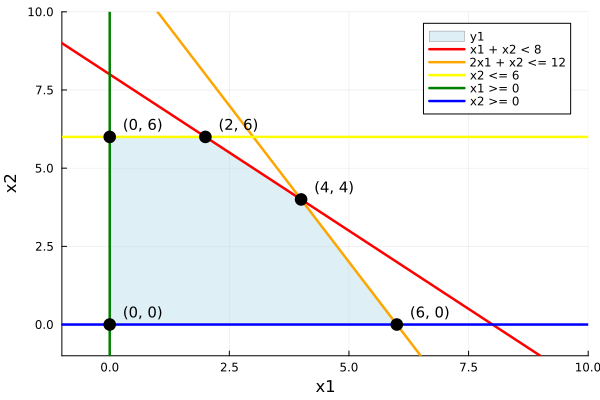

In [26]:
# Problem 2.1 
# build from Desmos result

# Given the three constaint equations 
slope = [-1, -2, 0]
intercept = [8, 12, 6]
label = ["x1 + x2 < 8", "2x1 + x2 <= 12", "x2 <= 6"]
line_color = [:red, :orange, :yellow]

# Corners, found from Desmos setup/visual 
corners = [(0, 0), (6, 0), (4, 4), (2, 6), (0, 6)]

plot_region = plot(Shape(first.(corners), last.(corners)), color=:lightblue, alpha=0.4, linewidth=0, xlims=(-1, 10), ylims=(-1, 10), xlabel="x1", ylabel="x2", legend=:topright)


x1_vals = -1:0.1:10
for i in 1:3
    plot!(plot_region, x1_vals, slope[i] .* x1_vals .+ intercept[i], color=line_color[i], linewidth=2.5, label=label[i])
end

# Constraints for non negativity 
vline!(plot_region, [0], color=:green, linewidth=2.5, label="x1 >= 0")
hline!(plot_region, [0], color=:blue, linewidth=2.5, label="x2 >= 0")

# Label each corner with its coordinates 
scatter!(plot_region, first.(corners), last.(corners), color=:black, markersize=7, label="")

for c in corners
    annotate!(plot_region, c[1] + 0.3, c[2] + 0.4, text("($(c[1]), $(c[2]))", 10, :left))
end

plot_region

#### Problem 2.2 (5)

Say whether each of the following points is optimal for this linear
program, and justify each answer.

1.  $(4, 4)$
2.  $(2, 6)$
3.  $(3, 5)$
4.  $(2, 2)$
5.  $(5, 3)$


### Answer to 2.2  

<div class="image-box">
   <img src='Answer to 2.2.jpeg'>
</div>





### Problem 3 (18) 

A lakeside city is under a consent order to reduce the stormwater
reaching its combined sewers and the phosphorus reaching its lake. It
plans to build two kinds of green infrastructure in one sewershed:

- **Bioretention cells** (rain gardens): shallow planted basins that
  collect runoff from the surrounding pavement and roofs and filter it
  through soil. Each cell drains an area several times its own size.
- **Permeable pavement**: parking-lot surfaces that let rain soak
  through into a stone reservoir underneath. It mostly handles the rain
  that falls on it.

Per acre built, the two options have the following performance and cost
characteristics. The costs are annualized: construction spread over the
lifetime of the infrastructure plus maintenance.

| Per acre built                       | Bioretention | Permeable pavement |
|:-------------------------------------|-------------:|-------------------:|
| Runoff captured (million gallons/yr) |            5 |                  2 |
| Phosphorus removed (kg/yr)           |            5 |                  1 |
| Annualized cost (\$1,000/yr)         |           50 |                 30 |

The consent order requires the city to capture at least 40 million
gallons of runoff per year and to remove at least 30 kg of phosphorus
per year. Suitable sites exist for at most 6 acres of bioretention, and
there are 15 acres of parking lots that could take permeable pavement.
With $B$ the acres of bioretention and $P$ the acres of permeable
pavement, the city’s problem is

$$\begin{aligned}
\min_{B, P} \quad & 50B + 30P && (\$1\text{,}000/\text{yr}) \\
\text{subject to:} \quad & 5B + 2P \geq 40 && \text{runoff captured (million gal/yr)} \\
& 5B + P \geq 30 && \text{phosphorus removed (kg/yr)} \\
& B \leq 6 && \text{bioretention sites (acres)} \\
& P \leq 15 && \text{parking lots (acres)} \\
& B, P \geq 0.
\end{aligned}$$

#### Problem 3.1 (2)

Sketch the feasible region, with $B$ on the horizontal axis, and label
every corner with its coordinates.




### Answer to 3.1   

The feasible region is the light blue shading area in this plot. The corners (3, 15), (6,15), (6,5) and (4,10) are also labeled. 

<div class="image-box">
   <img src='Answer to 3.1.png'>
</div>



Desmos reference to find corners: 
<div class="image-box">
   <img src='Desmos ref P3.png'>
</div>





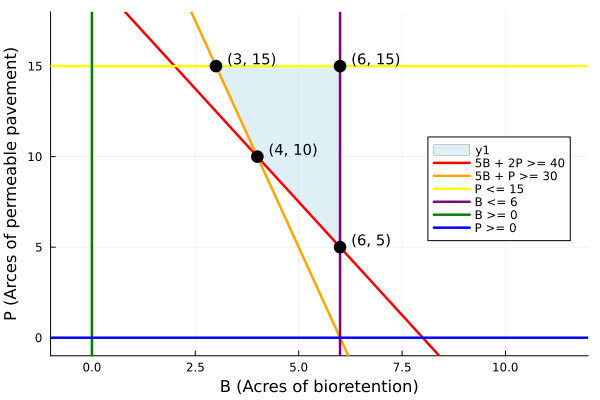

In [30]:
# Problem 3.1 sketch 

# Need B on x axis, so rewrite each consrtaint to be P = ...*B + .... 

slope = [-2.5, -5, 0]
intercept = [20, 30, 15]
label = ["5B + 2P >= 40", "5B + P >= 30", "P <= 15"]
line_color = [:red, :orange, :yellow]

# Corners, from Desmos  
corners_p3 = [(3, 15), (4, 10), (6, 5), (6, 15)]

plot_region = plot(Shape(first.(corners_p3), last.(corners_p3)), color=:lightblue, alpha=0.4, linewidth=0, xlims=(-1, 12), ylims=(-1, 18), xlabel="B (Acres of bioretention)", ylabel="P (Arces of permeable pavement)", legend=:right)

B_vals = -1:0.1:15
for i in 1:3
    plot!(plot_region, B_vals, slope[i] .* B_vals .+ intercept[i], color=line_color[i], linewidth=2.5, label=label[i])
end

# B <= 6 is region to the right of fixed x=B = 6 
vline!(plot_region, [6], color=:purple, linewidth=2.5, label="B <= 6")

# Constraints for non negativity
vline!(plot_region, [0], color=:green, linewidth=2.5, label="B >= 0")
hline!(plot_region, [0], color=:blue, linewidth=2.5, label="P >= 0")

# Label each corner with its coordinates
scatter!(plot_region, first.(corners_p3), last.(corners_p3), color=:black, markersize=7, label="")

for c in corners_p3
    annotate!(plot_region, c[1] + 0.3, c[2] + 0.4, text("($(c[1]), $(c[2]))", 10, :left))
end

plot_region

#### Problem 3.2 (2)

Find the optimal plan, using level lines of the cost or by evaluating
the cost at each corner, and report the minimum annual cost.

### Answer to 3.2 
The optimal plan would be the combination of B and P that costs the least, which means we find (B,P) that gives the minimum of the objective function 50B + 30P. 
The cost at the corner (3,15) is 600 thousands dollar per year. 
The cost at the corner (4, 10) is 500 thousands dollar per year.
The cost at the corner (6,15) is 750 thousands dollar per year. 
The cost at the corner (6, 5) is 450 thousands dollar per year, which is the smallest cost out of the four corners. Thus, **the optimal plan is B = 6 acres of bioretenion and P = 5 acres of permeable pavement, with the minimum annual cost of 450 thousands of dollars.**


In [31]:
# Evulate the cost using 50B + 30P at each corner 

for c in corners_p3
    println("Corner ", c, " cost = ", 50 * c[1] + 30 * c[2])
end

Corner (3, 15) cost = 600
Corner (4, 10) cost = 500
Corner (6, 5) cost = 450
Corner (6, 15) cost = 750


#### Problem 3.3 (1)

Which constraints are binding at the optimum?

### Answer to 3.3    

At the optimum, the **constraints of runoff captured (5B + 2P >= 40) and biorention sites (B <= 6) are binding**. 

<div class="image-box">
   <img src='Answer to 3.3.jpeg'>
</div>

#### Problem 3.4 (4)

Find the shadow prices of the two binding constraints, with units. One
way: relax each binding constraint by one unit, find where the optimal
corner moves, and compute how much the cost falls. You can check your
answer with the method from lecture, writing the cost coefficients as a
combination of the binding constraints’ coefficients.


### Answer to P3.4 
<div class="image-box">
   <img src='Answer to P3.4.jpeg'>
</div>

#### Problem 3.5 (1)

The shadow price of the phosphorus constraint is zero. What does that
mean for the city?

### Answer to P3.5 
The shadow price of phosphorus constraint is zero because this is a slack constraint as the phosphorus removed is 35 kg/yr, which is 5 kg/yr more than the current lower bound of 30 kg/yr for the constraint. Thus, for the city, their regulation for phosophrus removed can be further increased without impacting the optimal solution and the minimum cost at the optimum. 



#### Problem 3.6 (2)

A school district offers a 4-acre site for bioretention, but only as a
single lease, at \$60,000 per year for the whole site. Using only the
shadow price of the bioretention-site constraint, estimate how much 4
more acres would save the city each year. On that estimate, should the
city sign the lease?

### Answer to P3.6
<div class="image-box">
   <img src='Answer to 3.6.jpeg'>
</div>

#### Problem 3.7 (3)

Raise the bioretention limit from 6 to 10 acres. Find the new optimal
plan and its annual cost by hand, by extending your sketch from Problem
3.1.


### Answer to 3.7 
With the help from Desmos, we saw that as the constraint of B (a verticle line on the sketch) moves toward to the right, from 6 to 10, the intersection made by constraint on biorention side B and the runoff constraint 5B + 2P >= 40 moves to the right as well. Also, corners (3,15) and (4,10) on the left hand side of the feasible region are unchanged, so their annual cost remained as 600 and 500 thousands per year. For the new corners that appear (got updated) for this new feasible region, we evaluate their annual cost.

For (10,15), 50(10) + 30(15) = 950 thousands of dollars per year  
For (10, 0), 50(10) + 30(0) = 500 thousands of dollars per year 

For (8, 0), 50(8) + 30(0) = 400 thousands of dollars per year 

**The new optimal plan is (B, P) = (8,0) because it has the smallest annual cost of 400 thousands of dollars per year.** 


Extended sketch, with the lighter blue combined with the darker blue shaded region is the new feasible region (where the darker blue shaded part being the overlap with the old feasible region): 
<div class="image-box">
   <img src='Answer to 3.7.png'>
</div>


Reference of Desmos: 
<div class="image-box">
   <img src='Desmos for 3.7.png'>
</div>





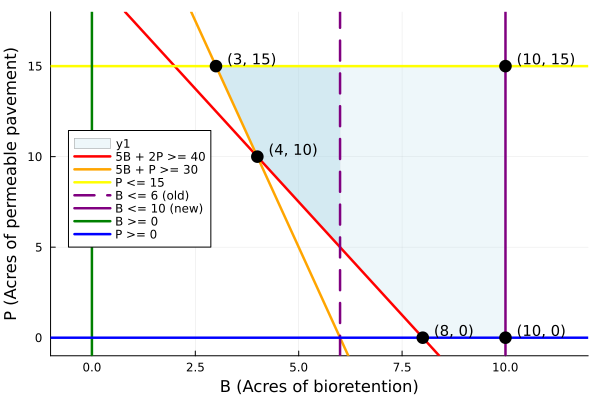

In [35]:
# Update for 3.7 

slope = [-2.5, -5, 0]
intercept = [20, 30, 15]
label = ["5B + 2P >= 40", "5B + P >= 30", "P <= 15"]
line_color = [:red, :orange, :yellow]

# Updated corners 
corners_p3 = [(3, 15), (4, 10), (8, 0), (10, 0), (10, 15)]

# Old corners from 3.1 to be plotted as the old region 
corners_old = [(3, 15), (4, 10), (6, 5), (6, 15)]

plot_region = plot(Shape(first.(corners_p3), last.(corners_p3)), color=:lightblue, alpha=0.2, linewidth=0, xlims=(-1, 12), ylims=(-1, 18), xlabel="B (Acres of bioretention)", ylabel="P (Acres of permeable pavement)", legend=:left)
plot!(plot_region, Shape(first.(corners_old), last.(corners_old)), color=:lightblue, alpha=0.4, linewidth=0, label="")

B_vals = -1:0.1:15
for i in 1:3
    plot!(plot_region, B_vals, slope[i] .* B_vals .+ intercept[i], color=line_color[i], linewidth=2.5, label=label[i])
end


vline!(plot_region, [6], color=:purple, linewidth=2.5, linestyle=:dash, label="B <= 6 (old)") 
vline!(plot_region, [10], color=:purple, linewidth=2.5, label="B <= 10 (new)") # New limit is B <= 10 feasible region is to the LEFT of each line

# Constraints for non negativity
vline!(plot_region, [0], color=:green, linewidth=2.5, label="B >= 0")
hline!(plot_region, [0], color=:blue, linewidth=2.5, label="P >= 0")

# Label each corner with its coordinates
scatter!(plot_region, first.(corners_p3), last.(corners_p3), color=:black, markersize=7, label="")

for c in corners_p3
    annotate!(plot_region, c[1] + 0.3, c[2] + 0.4, text("($(c[1]), $(c[2]))", 10, :left))
end

plot_region

#### Problem 3.8 (1)

How much does the city actually save with the 10-acre limit, and should
it sign the lease?

#### Problem 3.9 (2)

Look at your plan from Problem 3.7. Why is the shadow-price estimate
from Problem 3.6 wrong for a change this large?


### Problem 4 (12) 

Nitrogen from farms and wastewater treatment plants feeds algal blooms
in rivers, reservoirs and estuaries. A state agency is setting limits on
the nitrogen load reaching three points on a river: a drinking-water
**intake**, a **reservoir**, and the **estuary** at the river’s mouth.
Six sources release nitrogen to the river. Going downstream, the river
passes the upper farms and an upstream town’s treatment plant, then the
intake; then the middle farms and a city’s treatment plant, then the
reservoir; then the lower farms and a coastal town’s treatment plant,
and then it reaches the estuary.

Not all the nitrogen a source releases reaches each point downstream of
it: plants and algae take some up, bacteria return some to the air, and
the reservoir traps about half of what flows into it. A source’s
**delivery ratio** to a point is the fraction of its nitrogen that
reaches that point; it is 0 for a point upstream of the source. Each
source can cut its nitrogen, with cover crops and buffer strips on the
farms or upgrades at the treatment plants, up to a maximum and at a cost
per kg removed. Loads and removals are in kg of nitrogen per day:

| Source                | Load with no cuts | Maximum removal | Cost per kg removed |
|:----------------------|------------------:|----------------:|--------------------:|
| Upper farms           |             1,000 |             300 |              \$3.50 |
| Upstream town’s plant |               200 |             160 |                 \$5 |
| Middle farms          |             1,200 |             360 |                 \$4 |
| City’s plant          |             1,500 |           1,200 |                 \$8 |
| Lower farms           |               800 |             240 |                 \$6 |
| Coastal town’s plant  |               300 |             240 |                 \$7 |

| Delivery ratio        | Intake | Reservoir | Estuary |
|:----------------------|-------:|----------:|--------:|
| Upper farms           |    0.4 |       0.3 |    0.15 |
| Upstream town’s plant |    0.8 |       0.6 |     0.3 |
| Middle farms          |      0 |       0.6 |     0.3 |
| City’s plant          |      0 |       0.8 |     0.4 |
| Lower farms           |      0 |         0 |     0.6 |
| Coastal town’s plant  |      0 |         0 |     0.9 |

The limits are 500 kg/day at the intake, 1,500 kg/day at the reservoir
and 1,200 kg/day at the estuary. The agency wants the cheapest set of
cuts that meets all three.

With six decision variables, you can’t draw the feasible region, and it
has far too many corners to check by hand. The code below writes the
problem as a linear program in `JuMP` and solves it; you only need to
run it. The shadow prices then do the work the picture did in Problems 2
and 3: they explain why the optimal plan looks the way it does.

In [3]:
source_name = ["Upper farms", "Upstream town", "Middle farms",
    "City", "Lower farms", "Coastal town"]
nitrogen_load = [1000, 200, 1200, 1500, 800, 300]   # [kg/day] with no cuts
max_removal = [300, 160, 360, 1200, 240, 240]       # [kg/day]
removal_cost = [3.5, 5, 4, 8, 6, 7]                 # [$ per kg removed]

point_name = ["Intake", "Reservoir", "Estuary"]
load_limit = [500, 1500, 1200]                      # [kg/day]
# delivery[j, i]: the fraction of source i's nitrogen that reaches point j
delivery = [0.4  0.8  0    0    0    0;
            0.3  0.6  0.6  0.8  0    0;
            0.15 0.3  0.3  0.4  0.6  0.9]

n_sources = length(nitrogen_load)
n_points = length(load_limit)

nutrients = Model(HiGHS.Optimizer)
set_silent(nutrients)

# removal at each source [kg/day], up to its maximum
@variable(nutrients, 0 <= removal[i in 1:n_sources] <= max_removal[i])
# daily cost [$/day]
@objective(nutrients, Min,
    sum(removal_cost[i] * removal[i] for i in 1:n_sources))
# the nitrogen reaching each point [kg/day] stays within its limit
@constraint(nutrients, limit[j in 1:n_points],
    sum(delivery[j, i] * (nitrogen_load[i] - removal[i])
        for i in 1:n_sources) <= load_limit[j])

optimize!(nutrients)
println("Daily cost: \$", round(objective_value(nutrients); digits=2))

# How much each source removes [kg/day]. Adding 0 after rounding
# turns a -0.0 from the solver into 0
for i in 1:n_sources
    kg_removed = round(value(removal[i]); digits=1) + 0
    println(source_name[i], ": removes ", kg_removed, " of at most ",
        max_removal[i], " kg/day")
end

# The nitrogen reaching each point with the plan [kg/day], and the
# shadow price of the point's limit
reaching = zeros(n_points)
for j in 1:n_points
    for i in 1:n_sources
        kg_left = nitrogen_load[i] - value(removal[i])
        reaching[j] = reaching[j] + delivery[j, i] * kg_left
    end
    limit_price = round(shadow_price(limit[j]); digits=2) + 0
    println(point_name[j], ": ", round(reaching[j]; digits=1),
        " kg/day reaching, limit ", load_limit[j],
        " kg/day, shadow price ", limit_price)
end

Daily cost: $10040.0
Upper farms: removes 0.0 of at most 300 kg/day
Upstream town: removes 160.0 of at most 160 kg/day
Middle farms: removes 360.0 of at most 360 kg/day
City: removes 660.0 of at most 1200 kg/day
Lower farms: removes 140.0 of at most 240 kg/day
Coastal town: removes 240.0 of at most 240 kg/day
Intake: 432.0 kg/day reaching, limit 500 kg/day, shadow price 0.0
Reservoir: 1500.0 kg/day reaching, limit 1500 kg/day, shadow price -5.0
Estuary: 1200.0 kg/day reaching, limit 1200 kg/day, shadow price -10.0


#### Problem 4.1 (2)

Run the model. Report the daily cost, how much each source removes (as a
table), and the load reaching each of the three points, compared with
its limit.

**Answer:**
Daily cost: $10,040<br>
|Source|Removal (kg/day)| Maximum (kg/day)|
|:---|:---|:---|
|Upper farms| 0.0 | 300 |
|Upstream town| 160.0 | 160 |
|Middle farms|  360.0 | 360 |
|City|  660.0 | 1200 |
|Lower farms|  140.0 | 240 |
|Coastal town|  240.0 | 240 |

Intake: 432.0 kg/day reaching of at most 500 kg/day<br>
Reservoir: 1500.0 kg/day reaching of at most 1500 kg/day<br>
Estuary: 1200.0 kg/day reaching of at most 1200 kg/day

#### Problem 4.2 (3)

Which limits bind? Report the shadow price of each limit, as a positive
number with units.

**Answer:**

The reservoir and estuary are binding limits.<br>
The shadow prices were produced as a negative number since this is a minimization problem, but they can be interpreted as positive numbers that would decrease the objective function.<br>
Reservoir shadow price: 5 (\$/day)/(kg/day) = *5 \$/kg*<br>
Estuary shadow price: 10 (\$/day)/(kg/day) = *10 \$/kg*<br>

#### Problem 4.3 (4)

Write $d_{ji}$ for source $i$’s delivery ratio to point $j$ and $c_i$
for its cost per kg removed. Removing 1 more kg/day at source $i$ lowers
the load reaching each point $j$ by $d_{ji}$ kg/day. With $\lambda_j$
the shadow price of point $j$’s limit (as a positive number), that
kilogram is worth

$$v_i = \sum_{j} \lambda_j d_{ji} \qquad (\$ \text{ per kg removed}).$$

Compute $v_i$ for each source and compare it with the source’s cost,
$c_i$. Use the comparison to explain why each source removes nothing,
less than its maximum, or its maximum.

**Answer:**

Let $i = \left\{
\begin{array}{ll}
1 & \text{Upper farms} \\
2 & \text{upstream town's plant} \\
3 & \text{middle farms} \\
4 & \text{city's plant} \\
5 & \text{lower farms} \\
6 & \text{coastal town's plant}
\end{array}
\right.$

Let $j = \left\{
\begin{array}{lll}
1 & \text{intake} & \lambda_1 = 0 \\
2 & \text{reservoir} & \lambda_2 = 5 \\
3 & \text{estuary} & \lambda_3 = 10
\end{array}
\right.$

$
\begin{aligned}
& V_1=\sum_{j=1}^3 \lambda_j d_{1 j}=0 \cdot 0.4+5 \cdot 0.3+10 \cdot 0.15=3 \\
& V_2=\sum_{j=1}^3 \lambda_j d_{2 j}=0 \cdot 0.8+5 \cdot 0.6+10 \cdot 0.3=6 \\
& V_3=\sum_{j=1}^3 \lambda_j d_{3 j}=0 \cdot 0+5 \cdot 0.6+10 \cdot 0.3=6 \\
& V_4=\sum_{j=1}^3 \lambda_j d_{4 j}=0 \cdot 0+5 \cdot 0.8+10 \cdot 0.4=8 \\
& V_5=\sum_{j=1}^3 \lambda_j d_{5 j}=0 \cdot 0+5 \cdot 0+10 \cdot 0.6=6 \\
& V_6=\sum_{j=1}^3 \lambda_j d_{6 j}=0 \cdot 0+5 \cdot 0+10 \cdot 0.9=9
\end{aligned}
$

|Source|Cost $c_i$ (\$)| Worth of removing 1kg/d $v_i$ (\$/kg)|
|:---|:---|:---|
|Upper farms| 3.5 | 3 |
|Upstream town| 5 | 6 |
|Middle farms|  4 | 6 |
|City|  8 | 8 |
|Lower farms|  6 | 6 |
|Coastal town|  7 | 9 |

All of the sources that have a worth lower than their cost have a 0 removal rate, the sources with worth equal to cost have a less than maximum removal rate, and the sources with worth higher than cost achieve their maximum removal rates.

|No removal|Less Than Maximum| Maximum|
|:---|:---|:---|
|Upper farms| City | Upstream town |
| | Lower farms | Middle farms |
| |   | Coastal town |


#### Problem 4.4 (3)

The upper farms are the cheapest source per kg removed, and the city’s
plant is the most expensive. Why does the plan cut nothing at the upper
farms, but more at the city’s plant than at any other source?

**Answer:**
The delivery ratios between the upper farms and the city's plant are significantly different, with the upper farms having low delivery ratios (0.3 to the reservoir, 0.15 to the estuary) due to the nitrogen being absorbed by plants or lost to the air before it reaches the receptors far downriver. On the other hand, the city's plant is closer to the receptors so more of its nitrogen will affect the bodies of water (0.8 to the reservoir, 0.4 to the estuary).

Additionally, the city's plant has a lost cost per kilogram of removal at both the reservoir and estuary.<br>
For the reservoir's cost: <br>
the upper farm must remove (1/0.3) 3.33 kg at a cost of \$3.50 for 11.655 \$/kg<br>
the city's plant must remove (1/0.8) 1.25 kg at a cost of \$8 for 10 \$/kg<br>
For the estuary's cost: <br>
the upper farm must remove (1/0.15) 6.67 kg at a cost of \$3.50 for 23.345 \$/kg<br>
the city's plant must remove (1/0.4) 2.5 kg at a cost of \$8 for 20 \$/kg<br>

For both of these reasons, the city's plant cuts more than any other source.


### Reference 
- https://discourse.julialang.org/t/add-tag-with-coordinates-to-plot-in-plots-jl/58972 Reference for label of coordinates on skretch 
- Desmos (https://www.desmos.com/calculator) as tool to visualize feasible region and help with sketch (of corners)